# 56Fe(n,n'): inelastic scattering in a structural material, predicted from the other isotopes

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xsml import data, features, splits, models, metrics, importance

In [2]:
# load the table and take neutron inelastic scattering between 0.1 and 20 MeV, unqualified cross sections
table = data.load()
inelastic = data.select(table, projectile="n", mt=4, e_min=1e5, e_max=2e7, plain=True)
inelastic = features.append(inelastic)
inelastic = inelastic.reset_index(drop=True)
inelastic["iso"] = data.isotope_id(inelastic.Z, inelastic.A)
print(len(inelastic), "points,", inelastic.iso.nunique(), "isotopes")
print(inelastic.reaction.value_counts().head(3))

35626 points, 56 isotopes
reaction
26-FE-56(N,INL)26-FE-56,,SIG      21464
11-NA-23(N,INL)11-NA-23,,SIG       3843
82-PB-207(N,INL)82-PB-207,,SIG     1738
Name: count, dtype: int64


In [3]:
# the target isotope is held out: none of its rows is used for training
Z_target = 26
A_target = 56
train_mask, test_mask = splits.leave_one_isotope_out(inelastic, Z_target, A_target)
train = inelastic[train_mask].reset_index(drop=True)
target = inelastic[test_mask].reset_index(drop=True)
splits.assert_no_leakage(train, target)
print(len(train), "training points,", len(target), "points of the target")
print(data.datasets(target)[["dataset", "author", "year", "points", "e_min_eV", "e_max_eV", "ds_flag", "ds_offset_dex"]])

14162 training points, 21464 points of the target
    dataset      author  year  ...    e_max_eV        ds_flag  ds_offset_dex
0  10529004       Perey  1971  ...   2129500.0             ok       0.116014
1  11700002  Barrows jr  1965  ...   2430000.0             ok       0.063234
2  23073004      Negret  2013  ...  17696400.0             ok       0.186117
3  23134005       Beyer  2014  ...  11348000.0             ok       0.203382
4  23313002      Dupont  1998  ...   2994600.0  normalisation      -0.304085
5  23313003      Dupont  1998  ...   2996270.0  normalisation      -0.264566
6  30656021  Shi Xiamin  1982  ...  14200000.0             ok      -0.065420
7  32201002       Korzh  1994  ...   1400000.0             ok       0.103239
8  41156006     Simakov  1992  ...  14100000.0             ok      -0.011604

[9 rows x 8 columns]


In [4]:
# all features: the energy and every nuclear property from the mass table
all_features = [
    "log10_energy", "Z", "N", "A", "atomic_mass_u", "mass_excess", "binding_energy", "B_per_A",
    "S_n", "S_p", "S_2n", "S_2p", "Q_alpha", "Q_beta_minus", "Q_ng", "Q_np", "Q_na", "Q_n2n",
    "N_minus_Z", "asymmetry", "Z_odd", "N_odd", "A_odd", "pairing",
    "Z_magic_dist", "N_magic_dist", "Z_magic", "N_magic", "P_factor", "A_third", "radius_fm",
]

model_all = models.xgboost()
model_all.fit(train[all_features], train.log10_sigma)
prediction = model_all.predict(target[all_features])
factor_all = metrics.rms_factor(target.log10_sigma, prediction)
print("all features, all rows: RMS factor on the target", round(factor_all, 2))

all features, all rows: RMS factor on the target 6.96


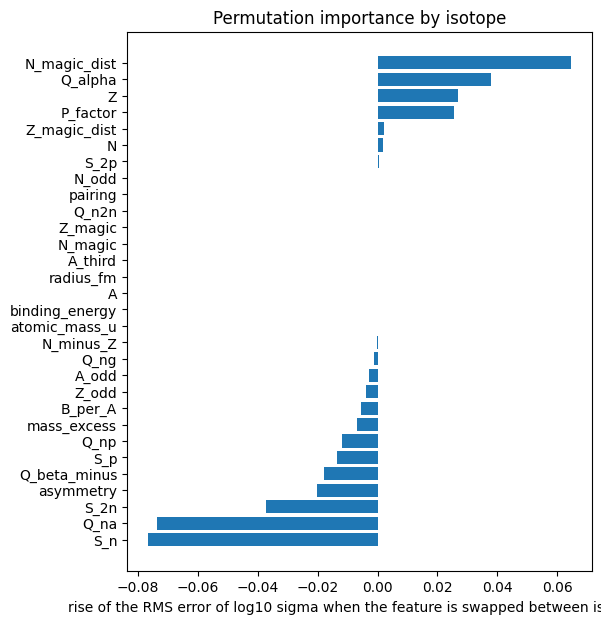

In [5]:
# naive feature importance: swap one feature between isotopes and see how much the error grows
# (measured on isotopes that the model did not train on; the energy is not an isotope property and is left out)
fold = splits.isotope_folds(train, 5)
fit_part = train[fold != 0]
check_part = train[fold == 0]
model_check = models.xgboost()
model_check.fit(fit_part[all_features], fit_part.log10_sigma)

names = []
rises = []
for name in all_features:
    if name == "log10_energy":
        continue
    result = importance.block_permutation(model_check, check_part[all_features], check_part.log10_sigma, check_part.iso, name, n_repeats=5)
    names.append(name)
    rises.append(result["mean"])
ranking = pd.Series(rises, index=names).sort_values()

plt.figure(figsize=(6, 7))
plt.barh(ranking.index, ranking.values)
plt.xlabel("rise of the RMS error of log10 sigma when the feature is swapped between isotopes")
plt.title("Permutation importance by isotope")
plt.show()

In [6]:
# trim: drop the datasets that the linter flags as offset or misshapen, and drop the other iron isotopes from training
flagged = ["normalisation", "shape", "normalisation+shape"]
train_trim = train[~train.ds_flag.isin(flagged)]
train_trim = train_trim[train_trim.Z != Z_target]
train_trim = train_trim.reset_index(drop=True)
target_trim = target[~target.ds_flag.isin(flagged)].reset_index(drop=True)
splits.assert_no_leakage(train_trim, target_trim, level="element")
print(len(train_trim), "training points after trimming,", train_trim.iso.nunique(), "isotopes,", len(target_trim), "target points")

12222 training points after trimming, 53 isotopes, 1651 target points


In [7]:
# three algorithms, cross-validated over isotopes on the trimmed training set
cv = splits.fold_splits(train_trim, 5)
algorithms = {
    "decision tree": models.decision_tree(),
    "random forest": models.random_forest(n_estimators=100),
    "XGBoost": models.xgboost(),
}
cv_scores = {}
target_scores = {}
fitted = {}
for name in algorithms:
    model = algorithms[name]
    rmse, out_of_fold = models.cv_rmse(model, train_trim[all_features], train_trim.log10_sigma, cv)
    cv_scores[name] = metrics.cluster_bootstrap(train_trim.log10_sigma, out_of_fold, train_trim.iso, n_boot=500)
    model.fit(train_trim[all_features], train_trim.log10_sigma)
    fitted[name] = model
    target_scores[name] = metrics.rms_factor(target_trim.log10_sigma, model.predict(target_trim[all_features]))
    print(name, "CV RMS factor", round(cv_scores[name]["value"], 2), "[", round(cv_scores[name]["low"], 2), ",", round(cv_scores[name]["high"], 2), "]",
          " target", round(target_scores[name], 2))

decision tree CV RMS factor 6.35 [ 3.21 , 9.58 ]  target 2.39
random forest CV RMS factor 2.64 [ 2.23 , 3.04 ]  target 2.64
XGBoost CV RMS factor 4.19 [ 2.24 , 5.93 ]  target 2.27


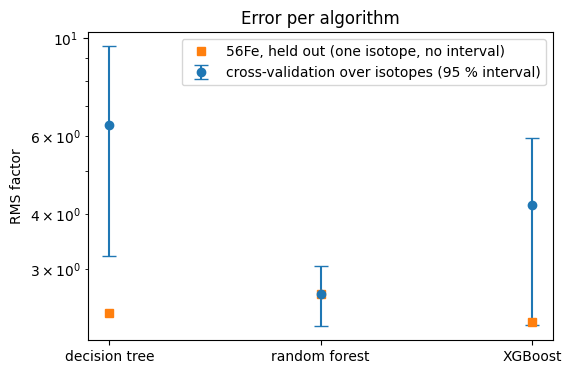

In [8]:
# error per algorithm, with the interval over isotopes
labels = list(cv_scores.keys())
values = np.array([cv_scores[name]["value"] for name in labels])
lows = np.array([cv_scores[name]["low"] for name in labels])
highs = np.array([cv_scores[name]["high"] for name in labels])
on_target = np.array([target_scores[name] for name in labels])

plt.figure(figsize=(6, 4))
plt.errorbar(labels, values, yerr=[values - lows, highs - values], fmt="o", capsize=5, label="cross-validation over isotopes (95 % interval)")
plt.plot(labels, on_target, "s", label="56Fe, held out (one isotope, no interval)")
plt.yscale("log")
plt.ylabel("RMS factor")
plt.title("Error per algorithm")
plt.legend()
plt.show()

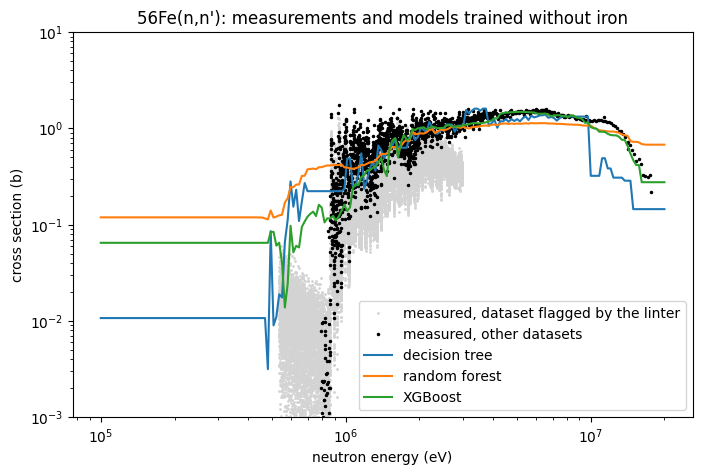

In [9]:
# the data of 56Fe and the three model curves
grid = pd.DataFrame({"projectile": "n", "Z": Z_target, "A": A_target, "MT": 4, "reaction": target.reaction.iloc[0],
                     "energy_eV": np.logspace(5, np.log10(2e7), 200), "sigma_b": 1.0})
grid = features.append(grid)
target_flagged = target[target.ds_flag.isin(flagged)]

plt.figure(figsize=(8, 5))
plt.loglog(target_flagged.energy_eV, target_flagged.sigma_b, ".", color="lightgrey", markersize=2, label="measured, dataset flagged by the linter")
plt.loglog(target_trim.energy_eV, target_trim.sigma_b, "k.", markersize=3, label="measured, other datasets")
for name in fitted:
    plt.loglog(grid.energy_eV, 10 ** fitted[name].predict(grid[all_features]), label=name)
plt.ylim(1e-3, 10)
plt.xlabel("neutron energy (eV)")
plt.ylabel("cross section (b)")
plt.title("56Fe(n,n'): measurements and models trained without iron")
plt.legend()
plt.show()

In [10]:
# log every score
log = "score_log_examples.csv"
metrics.log_score(log, model="XGBoost", features=all_features, split="56Fe held out, all rows", metric="rms_factor",
                  value=factor_all, n_groups=1, n_points=len(target), notes="no interval: one isotope")
for name in labels:
    metrics.log_score(log, model=name, features=all_features, split="5 isotope folds, unflagged datasets, no Fe", metric="rms_factor",
                      value=cv_scores[name]["value"], ci_low=cv_scores[name]["low"], ci_high=cv_scores[name]["high"],
                      n_groups=cv_scores[name]["n_groups"], n_points=cv_scores[name]["n_points"])
    metrics.log_score(log, model=name, features=all_features, split="56Fe held out, unflagged datasets, no Fe in training", metric="rms_factor",
                      value=target_scores[name], n_groups=1, n_points=len(target_trim), notes="no interval: one isotope")
print(pd.read_csv(log).tail(7)[["model", "split", "value", "ci_low", "ci_high"]].to_string())

            model                                                 split     value    ci_low   ci_high
7         XGBoost                               56Fe held out, all rows  6.958278       NaN       NaN
8   decision tree            5 isotope folds, unflagged datasets, no Fe  6.352907  3.206020  9.576790
9   decision tree  56Fe held out, unflagged datasets, no Fe in training  2.388572       NaN       NaN
10  random forest            5 isotope folds, unflagged datasets, no Fe  2.635429  2.225957  3.040463
11  random forest  56Fe held out, unflagged datasets, no Fe in training  2.637271       NaN       NaN
12        XGBoost            5 isotope folds, unflagged datasets, no Fe  4.189521  2.241424  5.928366
13        XGBoost  56Fe held out, unflagged datasets, no Fe in training  2.273429       NaN       NaN
